# Part 5 — Feature Engineering
## Ontario Winters and El Niño

**Business question:** *Before a winter begins, can we tell an Ontario municipality whether it is heading for a mild winter — so that salt, plough and overtime budgets can be set with better information than "last year plus inflation"?*

**Target KPI:** share of winters correctly anticipated as mild, measured against the rate a planner would get by assuming every winter is normal.

**Why now:** NOAA issued an El Niño advisory in August 2026 with a greater than 90% chance of a very strong El Niño through winter 2026-27. Municipal winter budgets are set in the autumn. If the historical record supports a planning adjustment, this is the year it matters.

### Where this sits in the project

This is the predictive arm of the Ontario El Niño study. The main analysis asks what past El Niño winters *looked like*; these three notebooks ask whether that history is strong enough to *anticipate* anything.

| Notebook | Covers |
|---|---|
| `05_feature_engineering.ipynb` | **Part 5 — this notebook** |
| `06_07_modeling_and_evaluation.ipynb` | Parts 6 and 7 |
| `08_business_recommendation.ipynb` | Part 8 |

> **Cleaning is not feature engineering.** The cleaning was done upstream by the project pipeline (`python/clean_data.py`) and verified in `docs/validation.md`. Section 0 below only applies the eligibility rules already defined there. Everything from Section 1 on is feature engineering.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.width', 130)
pd.set_option('display.max_columns', 40)

winters = pd.read_csv('../../data/processed/winter_kpis.csv')
print(f'{len(winters)} rows: {winters["city"].nunique()} locations x {winters["winter_year"].nunique()} winters')
print(f'Winters {winters["winter_year"].min()} to {winters["winter_year"].max()}')
winters[['city_name', 'winter_year', 'enso_class', 'enso_value',
         'mean_temp', 'temp_anomaly', 'snowfall_total_cm', 'days_below_m20']].head()

270 rows: 6 locations x 45 winters
Winters 1982 to 2026


,city_name,winter_year,enso_class,enso_value,mean_temp,temp_anomaly,snowfall_total_cm,days_below_m20
0,London,1982,Neutral,0.1,-7.013333,-2.933954,191.3,12.0
1,London,1983,El Nino,2.4,-1.541111,2.538268,58.6,0.0
2,London,1984,La Nina,-0.6,-6.012088,-1.932709,162.2,12.0
3,London,1985,La Nina,-0.8,-4.860000,-0.780621,215.0,7.0
4,London,1986,Neutral,-0.3,-5.732222,-1.652843,186.6,2.0


**The grain of this table is one location in one winter**, not one day. That single fact drives most of the decisions below — it means the dataset is small, and it means rows are not independent of each other.

## Section 0 — Eligibility recap (upstream work)

The project's rule is the WMO "3 and 5" standard: a winter is usable for temperature only if no month inside it has more than 3 consecutive or 5 total missing days. Winters that fail are **blank, not zero** — the reason the earlier analysis had to be rebuilt.

In [2]:
print(f'Total location-winters:            {len(winters)}')
print(f'Eligible for temperature:          {winters["temperature_pass"].sum()}')
print(f'Eligible for snowfall:             {winters["snowfall_pass"].sum()}')
print(f'Eligible for cold-day counts:      {winters["cold_days_pass"].sum()}')

Total location-winters:            270
Eligible for temperature:          253
Eligible for snowfall:             176
Eligible for cold-day counts:      225


This is the first constraint on the whole exercise. **Snowfall is only usable in 176 of 270 location-winters**, and at Thunder Bay — the station the south-to-north question leans on hardest — far fewer. Any target built on snow would be modelled mostly on the south.

Temperature is the best-measured variable in the dataset, so the target is built on temperature. That is a limitation, and it is a choice forced by data quality rather than by preference.

In [3]:
df = winters[winters['temperature_pass']].copy()
df = df.sort_values(['city', 'winter_year']).reset_index(drop=True)
print(f'{len(df)} eligible location-winters carried forward')
print(f'Dropped: {len(winters) - len(df)} that fail the temperature rule')

253 eligible location-winters carried forward
Dropped: 17 that fail the temperature rule


## Section 0b — which ENSO index does this file use?

Worth one check before building anything on top of it, because for most of this project's life the answer was *not* the one the project expected.

In [4]:
index_check = df[['winter_year', 'enso_index', 'enso_value', 'oni_djf', 'roni_djf',
                  'enso_class']].drop_duplicates('winter_year')

print('Index recorded in the processed file:', df['enso_index'].unique())
print()
disagree = index_check[index_check['enso_value'] != index_check['roni_djf']]
print(f'Winters where the stored value differs from RONI: {len(disagree)} of {len(index_check)}')
print()
print(index_check.head(6).to_string(index=False))

Index recorded in the processed file: <StringArray>
['RONI']
Length: 1, dtype: str

Winters where the stored value differs from RONI: 0 of 45

 winter_year enso_index  enso_value  oni_djf  roni_djf enso_class
        1982       RONI         0.1      0.0       0.1    Neutral
        1983       RONI         2.4      2.1       2.4    El Nino
        1984       RONI        -0.6     -0.6      -0.6    La Nina
        1985       RONI        -0.8     -1.0      -0.8    La Nina
        1986       RONI        -0.3     -0.4      -0.3    Neutral
        1987       RONI         1.5      1.2       1.5    El Nino


**This file is now on RONI — and for three weeks it was not.**

`python/config.py` sets `PRIMARY_INDEX = 'RONI'`, NOAA's official ENSO index since February 2026. Kiran switched it on 22 September. But `data/processed/winter_kpis.csv` is a *generated* file, and it was not regenerated after that change: until the pipeline was rerun on 13 October it still carried `enso_index = 'ONI'` from the September run.

Nothing was wrong with the code. The config said one thing and the committed data said another, because the data was older than the decision. A configuration change only takes effect for work that reruns after it.

**We still derive the class ourselves from `roni_djf` below**, rather than reading `enso_class`. Deriving it costs three lines and makes this notebook correct whichever version of the file it meets — including anyone's checkout from before the rerun. The cell after next checks the derived labels against the stored ones instead of trusting either.

In [5]:
EL_NINO, LA_NINA, STRONG = 0.5, -0.5, 1.5

df['ENSO_Value'] = df['roni_djf']
df['ENSO_Class'] = np.select(
    [df['ENSO_Value'] >= EL_NINO, df['ENSO_Value'] <= LA_NINA],
    ['El Nino', 'La Nina'], default='Neutral')

per_winter = df.drop_duplicates('winter_year')

stored_index = df['enso_index'].unique()[0]
disagreements = (per_winter['ENSO_Class'] != per_winter['enso_class']).sum()
print(f'Index recorded in the file:  {stored_index}')
print(f'Index this notebook uses:    RONI')
print(f'Winters where our derived class differs from the stored one: {disagreements}')
print()
if stored_index == 'RONI' and disagreements == 0:
    print('They agree. The pipeline has been rerun since the switch to RONI.')
else:
    print('They DISAGREE — this file predates the switch. Our derived labels are used.')
print()
print('Strong El Niño winters under each index:')
print('  ONI :', sorted(per_winter.loc[per_winter['oni_djf'] >= STRONG, 'winter_year']))
print('  RONI:', sorted(per_winter.loc[per_winter['roni_djf'] >= STRONG, 'winter_year']))

Index recorded in the file:  RONI
Index this notebook uses:    RONI
Winters where our derived class differs from the stored one: 0

They agree. The pipeline has been rerun since the switch to RONI.

Strong El Niño winters under each index:
  ONI : [1983, 1992, 1998, 2010, 2016, 2024]
  RONI: [1983, 1987, 1992, 1998, 2016]


**Three winters move in or out of the "strong" list depending on the index** — ONI counts 2010 and 2024, RONI counts 1987 instead. That is not a rounding detail. The strong events are where this project's entire signal lives, as Q5 shows, so the choice of index changes which winters the conclusions rest on.

> **Resolved in the repository.** `python python/run_pipeline.py` was rerun on 13 October 2026, regenerating `data/processed/` on RONI. Only four columns changed — `enso_index`, `enso_value`, `enso_class` and `strong_el_nino` — and every measurement in the daily files is byte-identical, which is the expected signature of an index switch and nothing else.

---
## Q1. What new feature could represent how strongly ENSO was acting in a winter?

*(Original question: what feature represents the customer's overall value? Same shape of problem — one number that captures the strength of the driver.)*

The project labels each winter with a DJF index value from NOAA. The raw value carries two different things at once: **direction** (positive is El Niño, negative is La Niña) and **magnitude** (how far from normal).

A model given only the signed value is forced to assume the effect is symmetric and linear — that −2.0 does the opposite of what +2.0 does, by the same amount. There is no reason to assume that about Ontario winters.

**Answer:** separate the two. Keep the signed value, and add its magnitude as its own feature.

In [6]:
df['ENSO_Strength'] = df['ENSO_Value'].abs()

print(df[['ENSO_Value', 'ENSO_Strength']].describe().round(2).to_string())
print()
print('Example: a strong El Niño and a strong La Niña have opposite values,')
print('but the same strength — and the model can now tell the difference between')
print('"strong, in some direction" and "near normal".')

       ENSO_Value  ENSO_Strength
count      253.00         253.00
mean        -0.07           0.94
std          1.11           0.59
min         -1.70           0.10
25%         -0.90           0.50
50%         -0.30           0.90
75%          0.60           1.40
max          2.40           2.40

Example: a strong El Niño and a strong La Niña have opposite values,
but the same strength — and the model can now tell the difference between
"strong, in some direction" and "near normal".


## Q2. Create a feature that captures the south-to-north question

*(Original hint: "think multiplication".)*

This is the project's central research question (BQ4): **does the El Niño effect differ between southern and northern Ontario?** A model with `enso_value` and `latitude` as separate columns can only learn "El Niño does X" and "northern stations are Y." It cannot learn "El Niño does more in the north" — that is an *interaction*, and in a linear model you have to build it by hand.

A product does exactly that.

In [7]:
# Centre latitude first, so the interaction is "north of average" x "ENSO",
# and the plain enso_value coefficient stays readable at average latitude.
lat_centre = df['latitude_approx'].mean()
df['ENSO_x_Latitude'] = df['ENSO_Value'] * (df['latitude_approx'] - lat_centre)

print(f'Latitude centred on {lat_centre:.2f} degrees N')
print()
example = df.loc[df['ENSO_Value'] > 1.5, ['city_name', 'winter_year', 'ENSO_Value',
                                          'latitude_approx', 'ENSO_x_Latitude']].head(6)
print(example.round(2).to_string(index=False))
print()
print('Same winter, same ENSO value — the interaction term separates north from south.')

Latitude centred on 44.87 degrees N

city_name  winter_year  ENSO_Value  latitude_approx  ENSO_x_Latitude
   London         1983         2.4            43.03            -4.43
   London         1992         2.1            43.03            -3.87
   London         1998         2.1            43.03            -3.87
   London         2016         2.1            43.03            -3.87
   Ottawa         1983         2.4            45.32             1.07
   Ottawa         1992         2.1            45.32             0.93

Same winter, same ENSO value — the interaction term separates north from south.


## Q3. How could you convert the outcome into a numerical target?

The business outcome is "was this a mild winter for this location?" The dataset holds `temp_anomaly` — how far that winter sat above or below **that location's own 1991–2020 average**. Using the anomaly rather than raw temperature is what makes Windsor and Thunder Bay comparable at all.

**Answer:** map it to 1/0 with a threshold that means something operationally.

In [8]:
MILD_THRESHOLD = 1.0   # degrees C above the location's own 1991-2020 baseline

df['Mild_Winter'] = (df['temp_anomaly'] >= MILD_THRESHOLD).astype(int)

rate = df['Mild_Winter'].mean()
print(f'Definition: a winter at least {MILD_THRESHOLD:.1f}°C above that location\'s baseline')
print()
print(df['Mild_Winter'].value_counts().rename({0: 'Not mild (0)', 1: 'Mild (1)'}).to_string())
print(f'\nBase rate: {rate:.1%} of eligible location-winters are mild')

Definition: a winter at least 1.0°C above that location's baseline

Mild_Winter
Not mild (0)    177
Mild (1)         76

Base rate: 30.0% of eligible location-winters are mild


**Why +1.0 °C and not "warmer than average".**

Splitting at zero would put a winter 0.1 °C above normal in the same class as one 3 °C above it, and would hand us a near 50/50 target that is mostly noise around the threshold. A full degree above a thirty-year normal is a winter a planner would actually notice.

It also leaves a base rate near **30%**, which matters for Part 7: a model that predicts "not mild" for every winter will be right about 70% of the time while being useless.

> **One honest caveat on the baseline.** The 1991–2020 normal is the project's documented convention, but for a winter in, say, 1995 it is partly computed from years that had not happened yet. It is a fixed, externally-defined reference rather than something fitted to our training split, so it does not leak the *target* — but it is not a quantity a planner in 1995 could have had either.

## Q4. Would `city` and `enso_class` be usable by every machine-learning algorithm?

**No.** Logistic regression multiplies each input by a coefficient; it cannot multiply `"Thunder Bay"` or `"El Nino"` by anything.

Both are *nominal* — there is no natural order to Brampton-versus-Ottawa, and El Niño/Neutral/La Niña is a category, not a ranking. Encoding them as 0/1/2 would invent an order the model would then take seriously. One-hot encoding is the correct choice.

In [9]:
demo = pd.get_dummies(df[['city_name', 'ENSO_Class', 'region']], drop_first=True).astype(int)
print(f'3 categorical columns -> {demo.shape[1]} numeric columns')
print(f'Rows: {len(demo)}, so the encoded matrix is {demo.shape[0]} x {demo.shape[1]}')
demo.head(3)

3 categorical columns -> 11 numeric columns
Rows: 253, so the encoded matrix is 253 x 11


,city_name_Ottawa,city_name_Sudbury,city_name_Thunder Bay,city_name_Toronto Pearson,city_name_Windsor,ENSO_Class_La Nina,ENSO_Class_Neutral,region_Northeast,region_Northwest,region_South-central,region_Southwest
0,0,0,0,0,0,0,1,0,0,0,1
1,0,0,0,0,0,0,0,0,0,0,1
2,0,0,0,0,0,1,0,0,0,0,1


> **These dummy columns are not saved.** They are shown to make the transformation concrete. In Notebook 2 the encoding happens inside a scikit-learn `Pipeline`, fitted on training data only — otherwise a category that appears in only one split silently produces mismatched columns.

Note the shape: **253 rows and 11 encoded columns before we add a single numeric feature.** With this little data, every column spent on a categorical variable is a column the model can overfit. That is a real argument for keeping the feature set small here.

## Q5. Could the ENSO index be transformed into meaningful groups?

**Yes — and unusually, we do not have to invent the bands.** NOAA already defines them, and the project's README adopts them. Using the official thresholds rather than quartiles means the groups mean the same thing here as they do in a NOAA bulletin.

One trap worth naming, because it cost us a winter. NOAA's thresholds are **inclusive**: an index of exactly +1.5 *is* a strong El Niño. `pd.cut`'s default behaviour is `right=True`, which makes the top band `(1.5, inf]` — exclusive. Winter 1987 sits at exactly RONI +1.5, so the default quietly drops it from the strong band and the count comes out as four winters instead of five.

The banding below is written out explicitly to match the published definition rather than a library default.

In [10]:
# NOAA's thresholds are inclusive: an index AT +1.5 is a strong El Niño.
# pd.cut's default (right=True) would exclude it, which silently drops winter 1987.
def assign_band(value):
    if value >= STRONG:
        return 'Strong El Niño'
    if value >= EL_NINO:
        return 'El Niño'
    if value <= -STRONG:
        return 'Strong La Niña'
    if value <= LA_NINA:
        return 'La Niña'
    return 'Neutral'

labels = ['Strong La Niña', 'La Niña', 'Neutral', 'El Niño', 'Strong El Niño']
df['ENSO_Band'] = pd.Categorical(df['ENSO_Value'].apply(assign_band),
                                 categories=labels, ordered=True)

band_summary = (df.groupby('ENSO_Band', observed=True)
                  .agg(Location_Winters=('Mild_Winter', 'size'),
                       Distinct_Winters=('winter_year', 'nunique'),
                       Mild_Rate=('Mild_Winter', 'mean'),
                       Mean_Anomaly=('temp_anomaly', 'mean')))
band_summary['Mild_Rate'] = (band_summary['Mild_Rate'] * 100).round(1).astype(str) + '%'
band_summary['Mean_Anomaly'] = band_summary['Mean_Anomaly'].round(2)
band_summary

,Location_Winters,Distinct_Winters,Mild_Rate,Mean_Anomaly
ENSO_Band,,,,
Strong La Niña,24,4,25.0%,0.40
La Niña,91,16,30.8%,-0.26
Neutral,52,9,23.1%,-0.98
El Niño,57,11,17.5%,-0.14
Strong El Niño,29,5,69.0%,1.70


**Two things in this table deserve a pause.**

**First, the bottom row.** Roughly seven out of ten location-winters in the Strong El Niño band were mild, against a 30% base rate. It is by far the largest effect anywhere in this project.

It rests on **5 distinct winters.** The rows are those same five winters seen from several locations, and locations in the same winter are not independent — they share one weather pattern and one ENSO value. The honest sample size is five, not 29, and the project's README says as much: there are only about five strong El Niño events in the entire record.

**Second, the row above it.** Moderate El Niño winters — index between +0.5 and +1.5 — were mild **less often than neutral winters**, and less often than La Niña winters.

So the association this project is built on is not a smooth gradient — it is a step. Nothing happens until the index clears +1.5, and then a great deal appears to. That matters for Part 8: "an El Niño is coming" and "a strong El Niño is coming" are not weaker and stronger versions of the same statement. On this record the first one carries no information at all.

Treat both rows as suggestive. Neither is evidence of a rule.

## Q6. Which variables are likely to be useful predictors?

Two tests: **can it be known before the winter starts**, and **does the data show any relationship**.

In [11]:
# Lag feature: last winter's outcome at the same location. Genuinely known in advance.
df['Prev_Anomaly'] = df.groupby('city')['temp_anomaly'].shift(1)
df['Prev_Was_Mild'] = df.groupby('city')['Mild_Winter'].shift(1)

before = len(df)
df = df.dropna(subset=['Prev_Anomaly']).reset_index(drop=True)
print(f'Dropped {before - len(df)} rows — the first eligible winter at each location has no predecessor')
print(f'{len(df)} location-winters remain, across {df["winter_year"].nunique()} distinct winters')

Dropped 6 rows — the first eligible winter at each location has no predecessor
247 location-winters remain, across 44 distinct winters


In [12]:
numeric = ['ENSO_Value', 'ENSO_Strength', 'ENSO_x_Latitude', 'latitude_approx',
           'winter_year', 'Prev_Anomaly', 'baseline_mean_temp']
signal = (df[numeric].corrwith(df['Mild_Winter'])
            .sort_values(key=abs, ascending=False)
            .rename('Correlation with a mild winter').to_frame().round(3))
signal

,Correlation with a mild winter
ENSO_Strength,0.221
ENSO_Value,0.205
winter_year,0.186
ENSO_x_Latitude,0.122
Prev_Anomaly,-0.089
baseline_mean_temp,-0.081
latitude_approx,0.078


In [13]:
summary = (df.groupby('ENSO_Class')
             .agg(Location_Winters=('Mild_Winter', 'size'),
                  Distinct_Winters=('winter_year', 'nunique'),
                  Mild_Rate=('Mild_Winter', 'mean'),
                  Mean_Anomaly=('temp_anomaly', 'mean'))
             .sort_values('Mild_Rate', ascending=False))
print((summary.assign(Mild_Rate=lambda t: (t['Mild_Rate'] * 100).round(1).astype(str) + '%',
                      Mean_Anomaly=lambda t: t['Mean_Anomaly'].round(2))).to_string())
print(f'\nOverall base rate: {df["Mild_Winter"].mean():.1%}')

            Location_Winters  Distinct_Winters Mild_Rate  Mean_Anomaly
ENSO_Class                                                            
El Nino                   86                16     34.9%          0.48
La Nina                  115                20     29.6%         -0.12
Neutral                   46                 8     26.1%         -0.73

Overall base rate: 30.8%


**Taken as a whole class, El Niño barely moves the needle.** El Niño winters are mild about 35% of the time against 26% in neutral winters. The direction is right, but the gap is small and most El Niño winters in this record were *not* mild by our definition.

Every correlation in the table above is small. Nothing here suggests a model will be able to call individual winters — and that matters more than the direction of the effect.

The real signal is not in the class. It is in the **strength**, as the band table in Q5 showed, and in **where** the station is, as the chart below shows.

### Does the effect change from south to north?

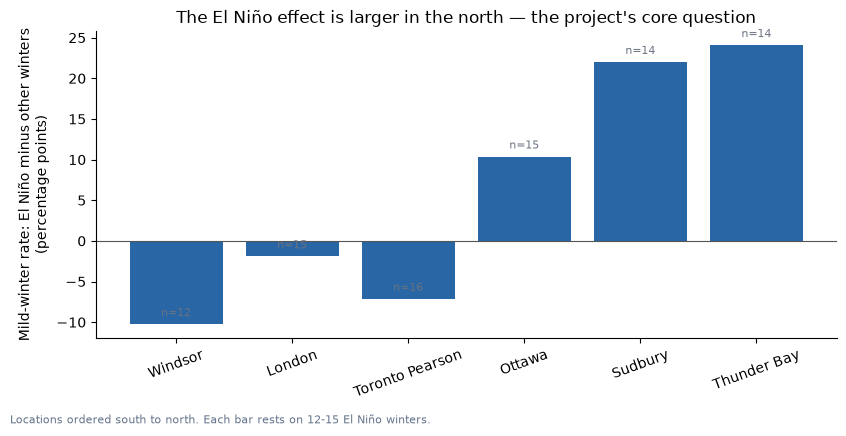

,Location,Latitude,El Niño mild rate,n (El Niño),Other winters mild rate,n (other),Difference
0,Windsor,42.28,17%,12,27%,26,-10 pts
1,London,43.03,27%,15,29%,28,-2 pts
2,Toronto Pearson,43.68,25%,16,32%,28,-7 pts
3,Ottawa,45.32,40%,15,30%,27,10 pts
4,Sudbury,46.63,50%,14,28%,25,22 pts
5,Thunder Bay,48.37,50%,14,26%,27,24 pts


In [14]:
gradient = []
for city, block in df.groupby('city_name'):
    el_nino = block[block['ENSO_Class'] == 'El Nino']['Mild_Winter']
    other = block[block['ENSO_Class'] != 'El Nino']['Mild_Winter']
    gradient.append({'Location': city,
                     'Latitude': block['latitude_approx'].iloc[0],
                     'El Niño mild rate': el_nino.mean(),
                     'n (El Niño)': len(el_nino),
                     'Other winters mild rate': other.mean(),
                     'n (other)': len(other),
                     'Difference': el_nino.mean() - other.mean()})
gradient = pd.DataFrame(gradient).sort_values('Latitude').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(gradient['Location'], gradient['Difference'] * 100, color='#2866a6')
ax.axhline(0, color='#555', linewidth=.8)
ax.set(ylabel='Mild-winter rate: El Niño minus other winters\n(percentage points)',
       title='The El Niño effect is larger in the north — the project\'s core question')
ax.tick_params(axis='x', rotation=20)
ax.spines[['top', 'right']].set_visible(False)
for i, (diff, n) in enumerate(zip(gradient['Difference'], gradient['n (El Niño)'])):
    ax.text(i, diff * 100 + 1, f'n={n}', ha='center', fontsize=8, color='#6b7280')
fig.text(.01, -.02, 'Locations ordered south to north. Each bar rests on 12-15 El Niño winters.',
         fontsize=8, color='#64748b')
fig.tight_layout()
plt.show()

gradient.assign(**{'El Niño mild rate': (gradient['El Niño mild rate'] * 100).round(0).astype(int).astype(str) + '%',
                   'Other winters mild rate': (gradient['Other winters mild rate'] * 100).round(0).astype(int).astype(str) + '%',
                   'Difference': (gradient['Difference'] * 100).round(0).astype(int).astype(str) + ' pts'})

**This is the most interesting thing in the notebook.** The gap between El Niño winters and everything else rises steadily with latitude: *negative* in the far south, near zero in the middle, and large at Sudbury and Thunder Bay.

An Ontario-wide statement about El Niño would average those together and describe nowhere.

That is the answer to BQ4, and it is the justification for the `ENSO_x_Latitude` feature built in Q2 — the pattern the interaction term exists to capture is visibly there.

It comes with the usual warning: each bar rests on 12 to 16 El Niño winters at one location, so no single percentage is solid. The *gradient across six locations* is the convincing part, not any one bar.

One winter shows the whole pattern on its own:

In [15]:
illustration = df[df['winter_year'] == 1987][['city_name', 'latitude_approx',
                                              'ENSO_Value', 'temp_anomaly', 'Mild_Winter']]
print('Winter 1987 — a strong El Niño at exactly RONI +1.5:')
print(illustration.sort_values('latitude_approx').round(2).to_string(index=False))

Winter 1987 — a strong El Niño at exactly RONI +1.5:
      city_name  latitude_approx  ENSO_Value  temp_anomaly  Mild_Winter
        Windsor            42.28         1.5          0.40            0
         London            43.03         1.5          0.03            0
Toronto Pearson            43.68         1.5         -0.20            0
         Ottawa            45.32         1.5          0.01            0
        Sudbury            46.63         1.5          1.92            1
    Thunder Bay            48.37         1.5          3.58            1


Same ocean, same winter, same index value. Thunder Bay came in **3.6 °C above its baseline** and Sudbury 1.9 °C above. Toronto came in slightly *below*. Windsor and London barely moved.

A single Ontario-wide number for winter 1987 would report "about half a degree above normal" and describe none of these six places.

**Likely useful predictors:**

| Variable | Why |
|---|---|
| `ENSO_Value` | The driver the entire project is about. Direct, and it shifts the odds. |
| `ENSO_x_Latitude` | Encodes the south-to-north pattern shown above. |
| `latitude_approx` | Northern stations have more variable winters, so more room to be 1 °C above normal. |
| `ENSO_Class` | The categorical form of the index. Coarser, but matches how NOAA communicates. |

**Likely weak:**

| Variable | Why |
|---|---|
| `Prev_Anomaly` | Weak correlation. Winters are close to independent — last winter says little about the next. |
| `winter_year` | A warming trend exists, but anomalies are measured against a fixed baseline, so some of it is already absorbed. |
| `baseline_mean_temp` | Nearly a proxy for latitude. Redundant. |

## Q7. What would you check before modeling?

Four checks. The last two are the ones that decide whether this project is honest.

In [16]:
print('1. MISSING VALUES')
features = numeric + ['Prev_Was_Mild']
missing = df[features].isna().sum()
print('   ' + ('None' if missing.sum() == 0 else missing[missing > 0].to_string()))

print('\n2. SAMPLE SIZE')
print(f'   {len(df)} rows — but only {df["winter_year"].nunique()} distinct winters')
print(f'   and {df["city_name"].nunique()} locations.')
print(f'   Roughly {df["Mild_Winter"].sum()} positive cases in total.')

1. MISSING VALUES
   None

2. SAMPLE SIZE
   247 rows — but only 44 distinct winters
   and 6 locations.
   Roughly 76 positive cases in total.


**247 rows is not 247 pieces of evidence.** Six locations observe the same 44 winters. For a feature like `ENSO_Value`, which takes one value per winter and is identical across all six locations, the effective sample size is **44**, not 247.

That is the single most important fact about this dataset, and it leads directly to check 3.

In [17]:
print('3. ARE THE ROWS INDEPENDENT?  <- the one that matters most here')
print()
example_winter = 2016
block = df[df['winter_year'] == example_winter][['city_name', 'ENSO_Value', 'ENSO_Class',
                                                 'temp_anomaly', 'Mild_Winter']]
print(f'Every eligible location in winter {example_winter}:')
print(block.round(2).to_string(index=False))
print()
print(f'The ENSO value is IDENTICAL across all {len(block)} rows — it is a property of')
print('the winter, not of the location. The anomalies are correlated too, because')
print('the same weather pattern crossed every station.')
print()
print(f'(Windsor is absent: it fails the eligibility rule for {example_winter}.)')

3. ARE THE ROWS INDEPENDENT?  <- the one that matters most here

Every eligible location in winter 2016:
      city_name  ENSO_Value ENSO_Class  temp_anomaly  Mild_Winter
         London         2.1    El Nino          2.78            1
         Ottawa         2.1    El Nino          2.96            1
        Sudbury         2.1    El Nino          2.82            1
    Thunder Bay         2.1    El Nino          2.92            1
Toronto Pearson         2.1    El Nino          3.04            1

The ENSO value is IDENTICAL across all 5 rows — it is a property of
the winter, not of the location. The anomalies are correlated too, because
the same weather pattern crossed every station.

(Windsor is absent: it fails the eligibility rule for 2016.)


**Why this will break a naive model.**

If rows are shuffled at random into training and test sets, winter 2016 will have some locations in training and others in test. The model sees "winter with RONI +2.4 was mild in Toronto" during training, and is then asked about "winter with RONI +2.4 in Ottawa." It has effectively seen the answer.

The score that comes back will be good and will mean nothing. Notebook 2 demonstrates exactly this, and the gap is large.

**The fix is to split by winter, never by row** — every location in a winter goes to the same side of the split. `GroupKFold(groups=winter_year)` in scikit-learn.

In [18]:
print('4. DATA LEAKAGE — is every feature knowable BEFORE the winter?')
print()
checks = {
    'latitude_approx':   'Yes — a fixed property of the station',
    'winter_year':       'Yes — known by definition',
    'Prev_Anomaly':      'Yes — last winter has already finished',
    'baseline_mean_temp':'Partly — the 1991-2020 normal is fixed, but overlaps the study period',
    'ENSO_Value (DJF)':  'NO — the December-February value is only final in March',
    'temp_anomaly':      'NO — this IS the target. Never a feature.',
    'mean_temp':         'NO — the target in another form',
    'snowfall_total_cm': 'NO — measured during the same winter',
    'days_below_m20':    'NO — measured during the same winter',
}
for feature, verdict in checks.items():
    mark = '  ' if verdict.startswith('Yes') else '!!'
    print(f'{mark} {feature:22} {verdict}')

4. DATA LEAKAGE — is every feature knowable BEFORE the winter?

   latitude_approx        Yes — a fixed property of the station
   winter_year            Yes — known by definition
   Prev_Anomaly           Yes — last winter has already finished
!! baseline_mean_temp     Partly — the 1991-2020 normal is fixed, but overlaps the study period
!! ENSO_Value (DJF)       NO — the December-February value is only final in March
!! temp_anomaly           NO — this IS the target. Never a feature.
!! mean_temp              NO — the target in another form
!! snowfall_total_cm      NO — measured during the same winter
!! days_below_m20         NO — measured during the same winter


### The honest problem with `enso_value`

The project labels each winter with its **December–February** index value. That number does not exist until the winter is over. A planner setting a budget in October cannot have it.

What they *can* have is NOAA's autumn forecast of it — which is a different number, carrying forecast error. NOAA issued its advisory for 2026-27 in August 2026 with better than 90% confidence, so a usable forecast genuinely exists. But it is not this column.

**So every result in Notebooks 2 and 3 is an upper bound.** We are giving the model the actual outcome of the ENSO season and asking it to predict the weather that accompanied it. A deployed version, using a forecast made months earlier, would do worse.

Three ways to handle this:

| Option | Verdict |
|---|---|
| Drop ENSO entirely | Removes the one variable the project exists to study. No. |
| Use it and say nothing | Dishonest. The model would be quietly unusable. |
| **Use it, label the result an upper bound, and state the gap in Part 8** | What we do. |

The target columns — `temp_anomaly`, `mean_temp` and the within-winter measurements — are a different matter and are simply excluded. They are the outcome, or they are measured during the winter we claim to be predicting.

### Does anything need scaling?

Yes, for logistic regression. `winter_year` runs near 2000 while `enso_value` sits between −2 and +3, and scikit-learn's default regularisation penalises large coefficients — so unscaled features get penalised for their units rather than their usefulness.

**Scaling is not done here.** It belongs inside the pipeline in Notebook 2, fitted on training data only. Scaling now, using the mean and standard deviation of all 247 rows, would leak test information into training.

---
## Saving the engineered dataset

In [19]:
keep = ['city', 'city_name', 'region', 'winter_year',
        'ENSO_Class', 'ENSO_Band', 'ENSO_Value', 'ENSO_Strength', 'ENSO_x_Latitude',
        'latitude_approx', 'baseline_mean_temp', 'Prev_Anomaly', 'Prev_Was_Mild',
        'temp_anomaly',      # kept for reporting only — NEVER a feature
        'Mild_Winter']

out = df[keep].copy()
out.to_csv('winter_features.csv', index=False)

print(f'Saved winter_features.csv — {len(out)} rows x {out.shape[1]} columns')
print(f'Distinct winters: {out["winter_year"].nunique()}  |  Locations: {out["city_name"].nunique()}')
print(f'Base rate preserved: {out["Mild_Winter"].mean():.1%}')
out.head()

Saved winter_features.csv — 247 rows x 15 columns
Distinct winters: 44  |  Locations: 6
Base rate preserved: 30.8%


,city,city_name,region,winter_year,ENSO_Class,ENSO_Band,ENSO_Value,ENSO_Strength,ENSO_x_Latitude,latitude_approx,baseline_mean_temp,Prev_Anomaly,Prev_Was_Mild,temp_anomaly,Mild_Winter
0,london,London,Southwest,1983,El Nino,Strong El Niño,2.4,2.4,-4.427668,43.03,-4.079379,-2.933954,0.0,2.538268,1
1,london,London,Southwest,1984,La Nina,La Niña,-0.6,0.6,1.106917,43.03,-4.079379,2.538268,1.0,-1.932709,0
2,london,London,Southwest,1985,La Nina,La Niña,-0.8,0.8,1.475889,43.03,-4.079379,-1.932709,0.0,-0.780621,0
3,london,London,Southwest,1986,Neutral,Neutral,-0.3,0.3,0.553458,43.03,-4.079379,-0.780621,0.0,-1.652843,0
4,london,London,Southwest,1987,El Nino,Strong El Niño,1.5,1.5,-2.767292,43.03,-4.079379,-1.652843,0.0,0.029379,0


---
## Part 5 summary

**Created:**

| Feature | Built from | Purpose |
|---|---|---|
| `Mild_Winter` | `temp_anomaly >= +1.0` | Numeric target, 31% base rate |
| `ENSO_Strength` | `abs(ENSO_Value)` | Magnitude separated from direction |
| `ENSO_x_Latitude` | `ENSO_Value x centred latitude` | Encodes the south-to-north question |
| `ENSO_Band` | `ENSO_Value` | NOAA's own categories, not invented quartiles |
| `Prev_Anomaly` | Last winter at the same location | Legitimate pre-winter information |

**What the data says before any model is built:**

1. As a class, El Niño barely matters: mild about **35%** of the time against **26%** in neutral winters.
2. The effect **grows with latitude**: slightly negative at Windsor, over 20 points at Sudbury and Thunder Bay.
3. **Strength is what matters, and the relationship is a step rather than a slope.** Roughly seven in ten strong El Niño location-winters were mild — across just **five** distinct winters. Moderate El Niño winters were mild *less* often than neutral ones.

**Three constraints carried into Notebook 2:**

1. **44 winters, not 247 rows.** Six locations share each winter; the ENSO value is identical across all six. The split must be by winter or the evaluation is fiction.
2. **The DJF index is not known in advance.** Results are an upper bound on what a planner could achieve.
3. **The base rate is 31%.** A model predicting "not mild" every time scores 69%, so accuracy cannot be the headline metric.